# Chest X-Ray Pneumonia Detection: training run (TensorFlow / Keras)

Trains DenseNet121 on the Kaggle chest X-ray dataset, evaluates it on the 624-image test set, and generates Grad-CAM explanations. Every figure and metric in the repo comes from this run.

**How to run**
1. *Runtime → Change runtime type →* **T4 GPU**
2. *Runtime →* **Run all** (about 30 min)
3. The last cell downloads `results.zip`. Save this notebook with its outputs too: *File → Download → Download .ipynb*

## 1. Environment

In [1]:
import tensorflow as tf, keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
assert gpus, "No GPU found: Runtime -> Change runtime type -> T4 GPU, then run all again."
!nvidia-smi -L

TensorFlow 2.21.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-7775c4a1-8723-8291-e6e7-c1318af82a27)


In [2]:
%cd /content
!rm -rf Chest_Xray_Disease_Detection
!git clone -q https://github.com/SWAPI03/Chest_Xray_Disease_Detection.git
%cd Chest_Xray_Disease_Detection
!git log --oneline -1
# Colab already ships TensorFlow, scikit-learn, OpenCV and seaborn, so nothing to install.
# (pip install -r requirements.txt would also pull in jupyter and break Colab's ipykernel.)

/content
/content/Chest_Xray_Disease_Detection
8059bde (HEAD -> main, origin/main, origin/HEAD) Stop reinstalling requirements in the Colab notebook


## 2. Dataset

Downloads [paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) with `kagglehub`. If the download asks for credentials, add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's *Secrets* panel (key icon) and rerun this cell.

The Kaggle `val/` folder only has 16 images, so `prepare_data.py` moves 10% of `train/` into `val/` (fixed seed).

In [3]:
import shutil
from pathlib import Path
import kagglehub

path = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
# The archive holds chest_xray/{train,val,test} plus a duplicate nested copy; use the shallowest.
src = min((p.parent for p in path.rglob("train") if (p / "NORMAL").is_dir()), key=lambda p: len(p.parts))
print("Source:", src)

dst = Path("data/raw")
if not dst.exists():
    for split in ["train", "val", "test"]:
        shutil.copytree(src / split, dst / split)
!python data/prepare_data.py

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Source: /kaggle/input/chest-xray-pneumonia/chest_xray

Dataset summary:
  train / NORMAL    :  1341 images
  train / PNEUMONIA :  3875 images
  val   / NORMAL    :     8 images
  val   / PNEUMONIA :     8 images
  test  / NORMAL    :   234 images
  test  / PNEUMONIA :   390 images

Fixing val split (Kaggle val/ is too small)…
  NORMAL: moved 134 images  train → val
  PNEUMONIA: moved 387 images  train → val

Final dataset:

Dataset summary:
  train / NORMAL    :  1207 images
  train / PNEUMONIA :  3488 images
  val   / NORMAL    :   142 images
  val   / PNEUMONIA :   395 images
  test  / NORMAL    :   234 images
  test  / PNEUMONIA :   390 images


## 3. A quick look at the data

  [train]  Normal: 1207  |  Pneumonia: 3488  |  Total: 4695
  [val]  Normal: 142  |  Pneumonia: 395  |  Total: 537
  [test]  Normal: 234  |  Pneumonia: 390  |  Total: 624


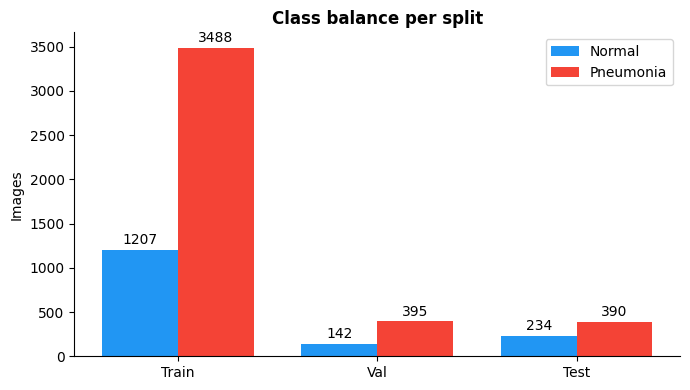

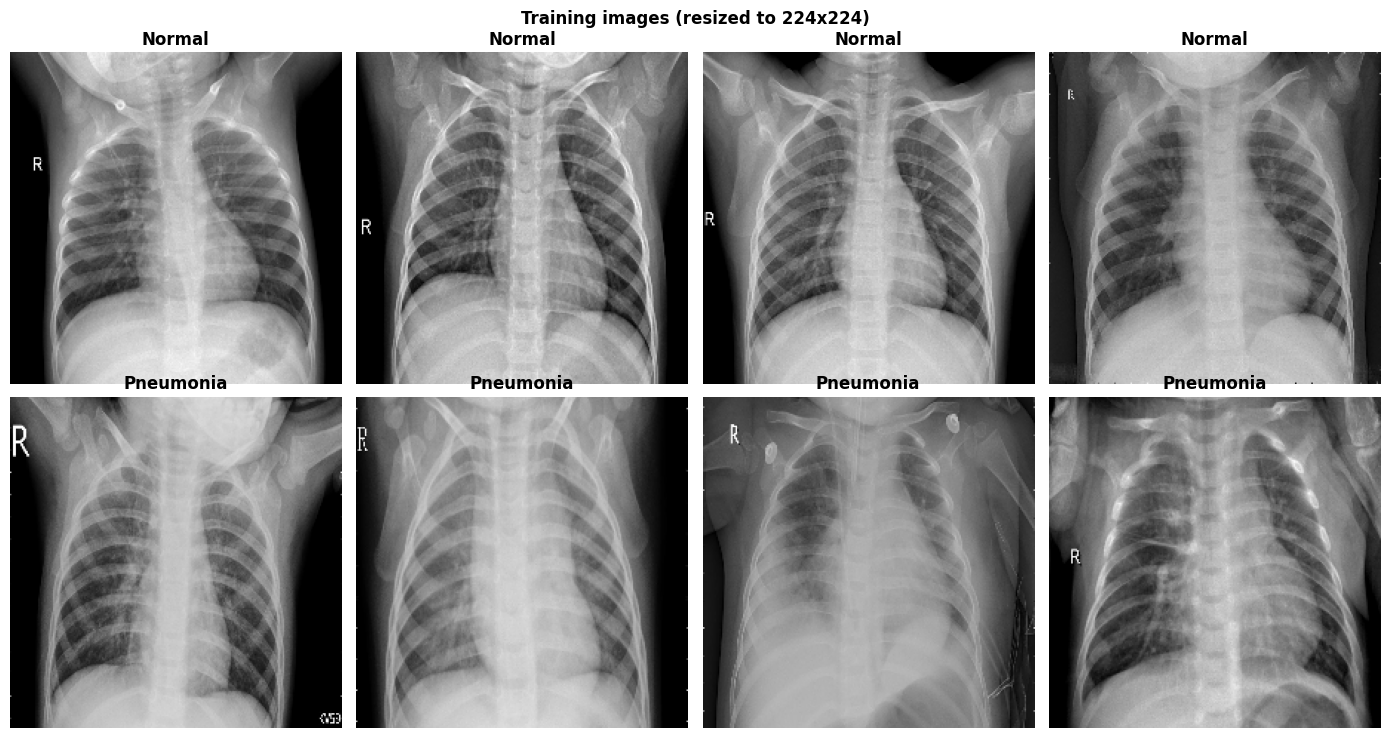

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from src.dataset import list_split, load_image, CLASSES

splits = {s: list_split("data/raw", s) for s in ["train", "val", "test"]}

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
for k, (cls, color) in enumerate(zip(CLASSES, ["#2196F3", "#F44336"])):
    n = [int((splits[s][1] == k).sum()) for s in splits]
    bars = ax.bar(x + (k - 0.5) * 0.38, n, 0.38, label=cls, color=color)
    ax.bar_label(bars, padding=2)
ax.set_xticks(x, [s.capitalize() for s in splits])
ax.set_ylabel("Images")
ax.set_title("Class balance per split", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.savefig("outputs/visualizations/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

paths, labels = splits["train"]
rng = np.random.default_rng(0)
picks = list(rng.choice(np.flatnonzero(labels == 0), 4, replace=False)) +         list(rng.choice(np.flatnonzero(labels == 1), 4, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), picks):
    ax.imshow(load_image(paths[i]))
    ax.set_title(CLASSES[labels[i]], fontweight="bold")
    ax.axis("off")
fig.suptitle("Training images (resized to 224x224)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/visualizations/sample_images.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Smoke test, then train

`main.py --mode train` trains, picks the epoch with the best validation AUC, then evaluates on the test set and writes the Grad-CAM figures.

In [5]:
!python main.py

11:42:35 | INFO | GPU : /physical_device:GPU:0
11:42:35 | INFO | Mixed precision: mixed_float16
11:42:36 | INFO | Running DEMO mode (synthetic data)…
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  Model : DENSENET121  |  Params: 7.0M  |  Trainable: 7.0M
11:42:44 | INFO | Forward pass OK  input=[4, 224, 224, 3]  output=[4, 1]

  Demo metrics (random baseline, not meaningful):
    accuracy: 0.5700
    precision: 0.5918
    recall: 0.5577
    specificity: 0.5833
    f1: 0.5743
    auc: 0.4323

  Pipeline OK. To train for real:
    1. Download dataset (see README → Setup)
    2. python main.py --mode train



In [6]:
!python main.py --mode train

11:42:52 | INFO | GPU : /physical_device:GPU:0
11:42:52 | INFO | Mixed precision: mixed_float16
11:42:52 | INFO | Loading data…
  [train]  Normal: 1207  |  Pneumonia: 3488  |  Total: 4695
  [val]  Normal: 142  |  Pneumonia: 395  |  Total: 537
  [test]  Normal: 234  |  Pneumonia: 390  |  Total: 624
11:42:55 | INFO | Building model…
  Model : DENSENET121  |  Params: 7.0M  |  Trainable: 7.0M
11:42:58 | INFO | Starting training…

  Model   : DENSENET121
  Epochs  : 20  |  LR: 0.0001  |  Steps/epoch: 146
  Policy  : mixed_float16
  Class weights: {0: 1.9449047224523612, 1: 0.6730217889908257}

Epoch 1/20

Epoch 1: val_auc improved from None to 0.99684, saving model to outputs/models/best_model.keras

Epoch 1: finished saving model to outputs/models/best_model.keras
146/146 - 508s - 3s/step - accuracy: 0.9236 - auc: 0.9845 - loss: 0.1630 - precision: 0.9832 - recall: 0.9126 - val_accuracy: 0.9702 - val_auc: 0.9968 - val_loss: 0.0760 - val_precision: 0.9847 - val_recall: 0.9747
Epoch 2/20
W00

## 5. Results

{
  "accuracy": 0.8462,
  "precision": 0.8037,
  "recall": 0.9974,
  "specificity": 0.594,
  "f1": 0.8902,
  "auc": 0.9429
}
Confusion matrix: {'true_negative': 139, 'false_positive': 95, 'false_negative': 1, 'true_positive': 389}
Best epoch: 14 of 16


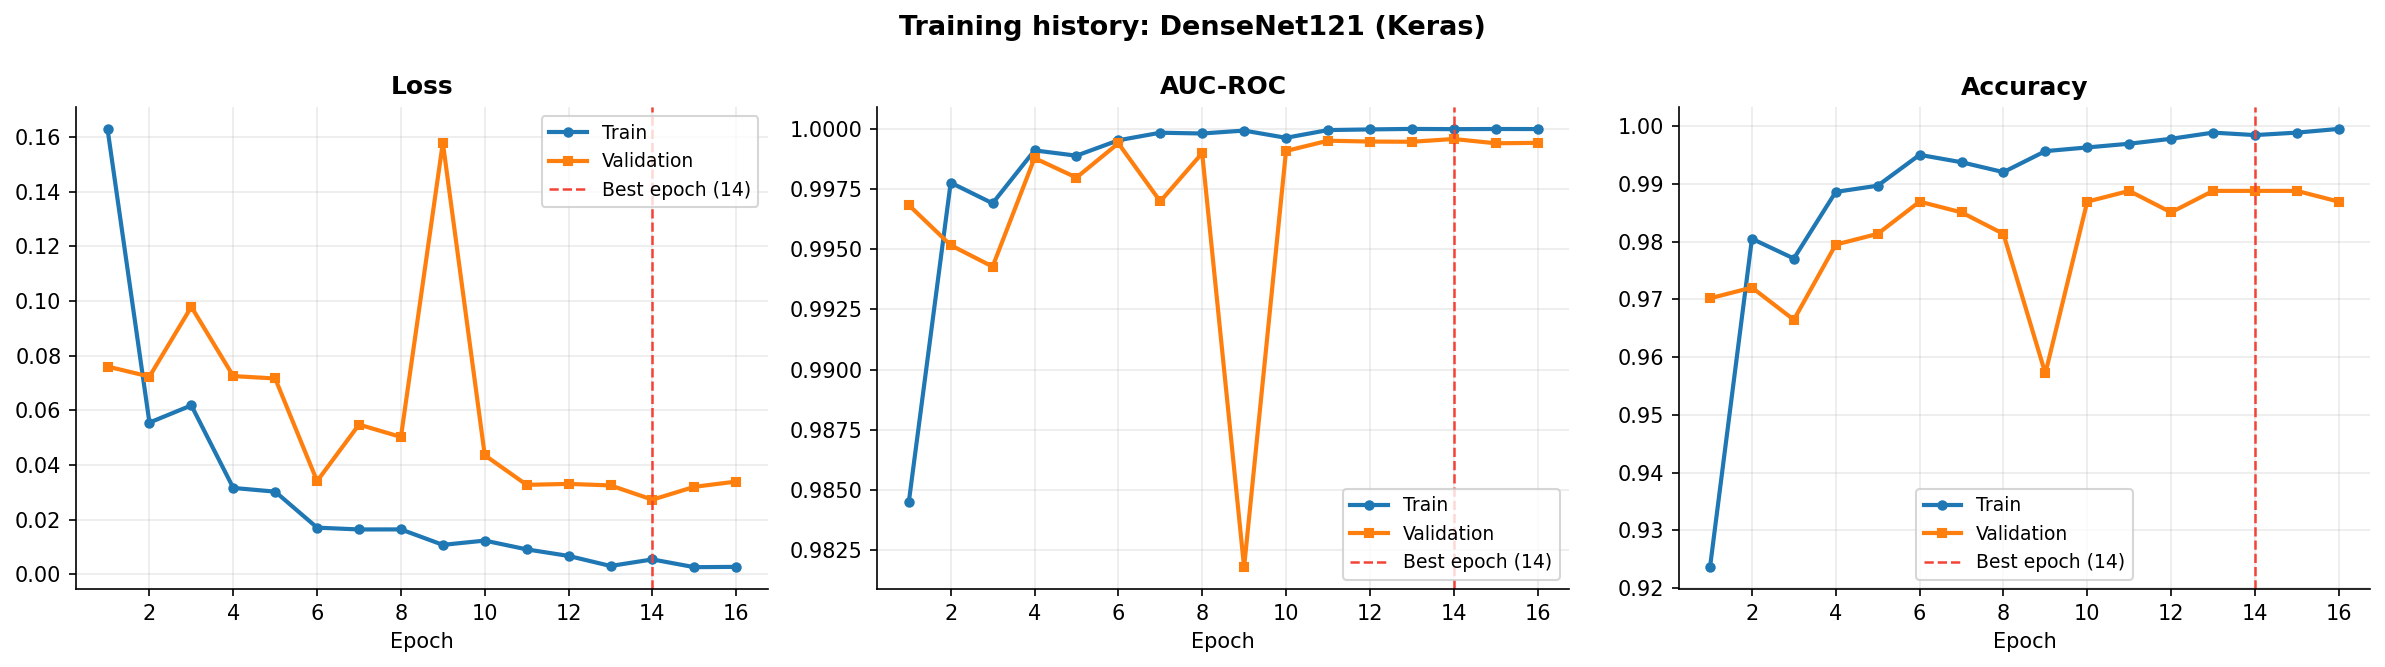

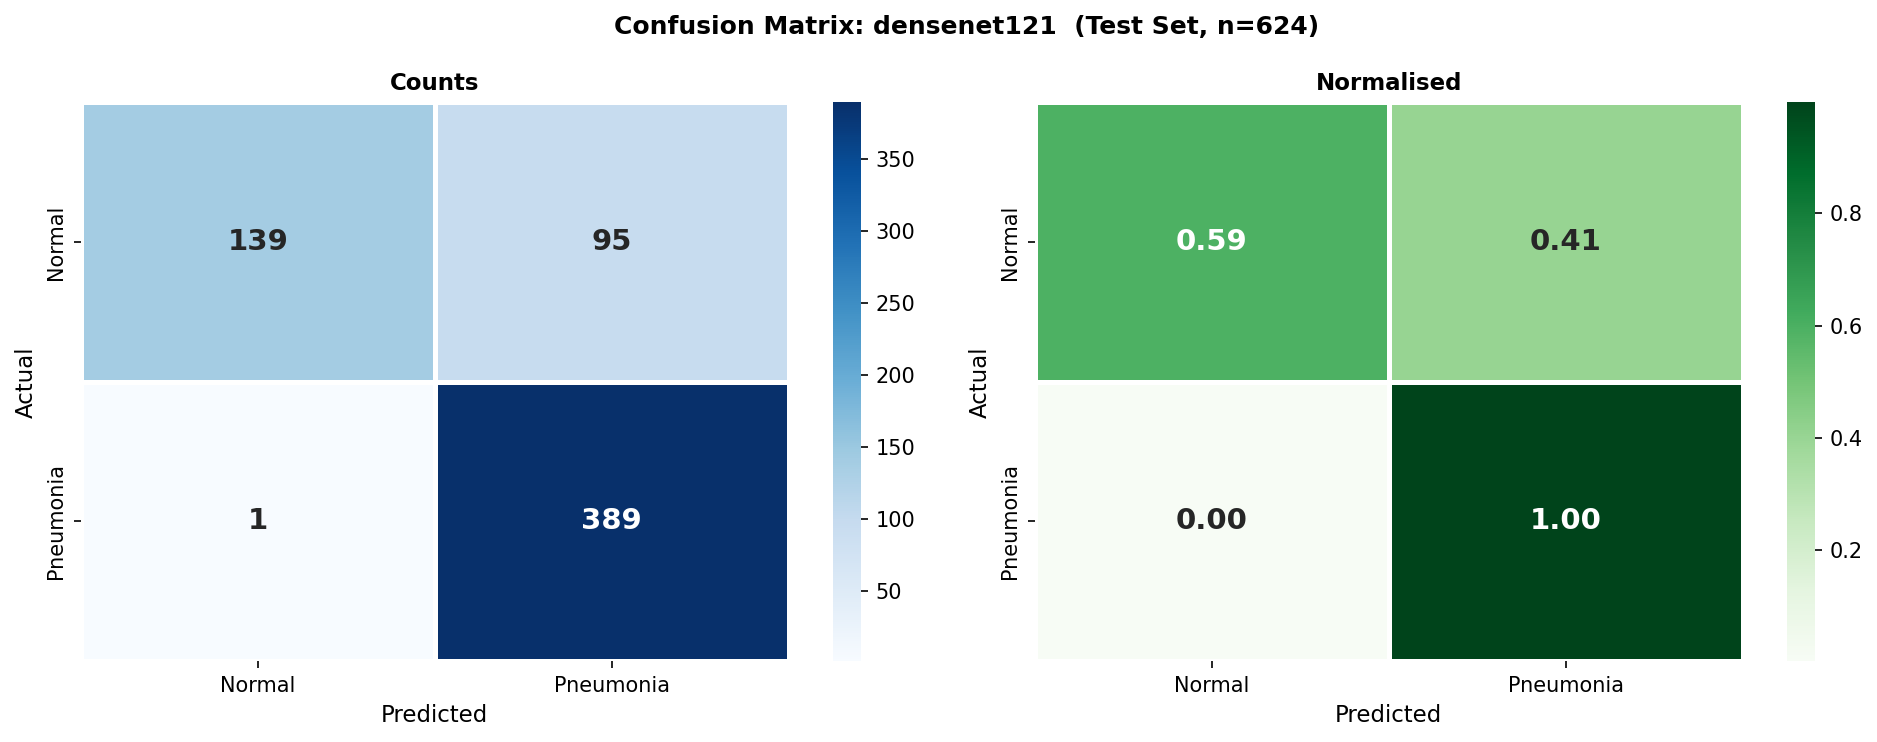

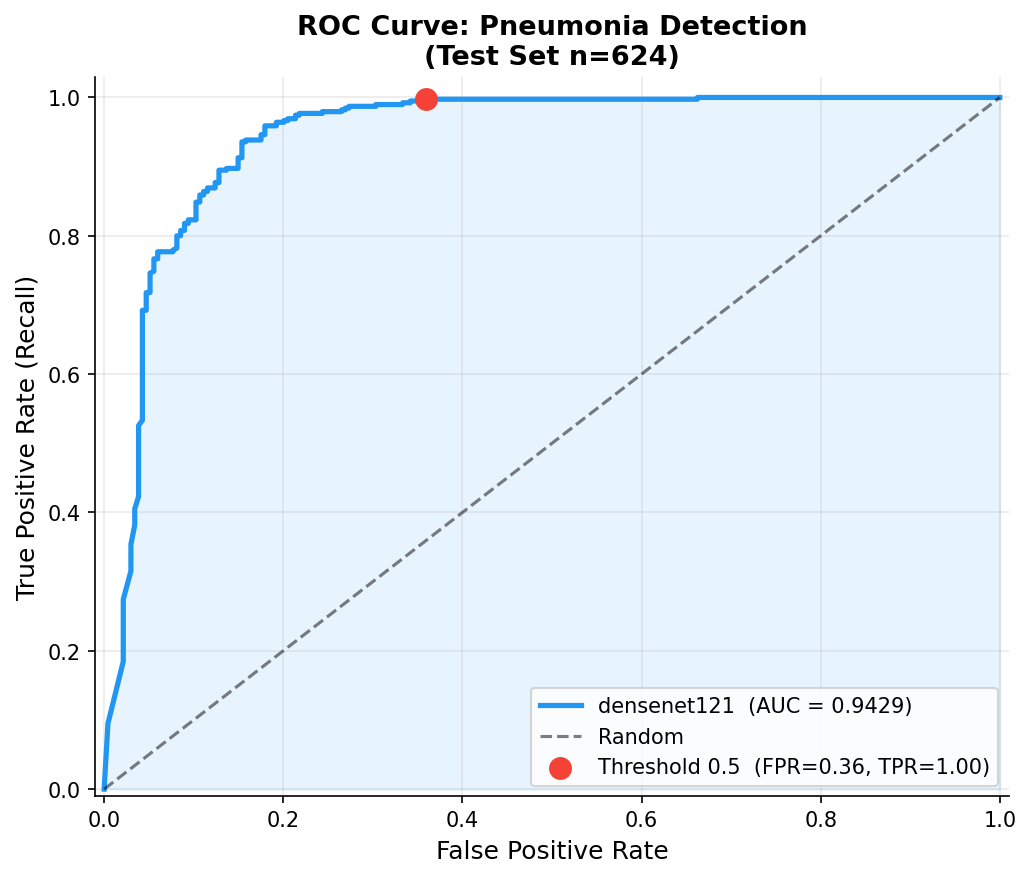

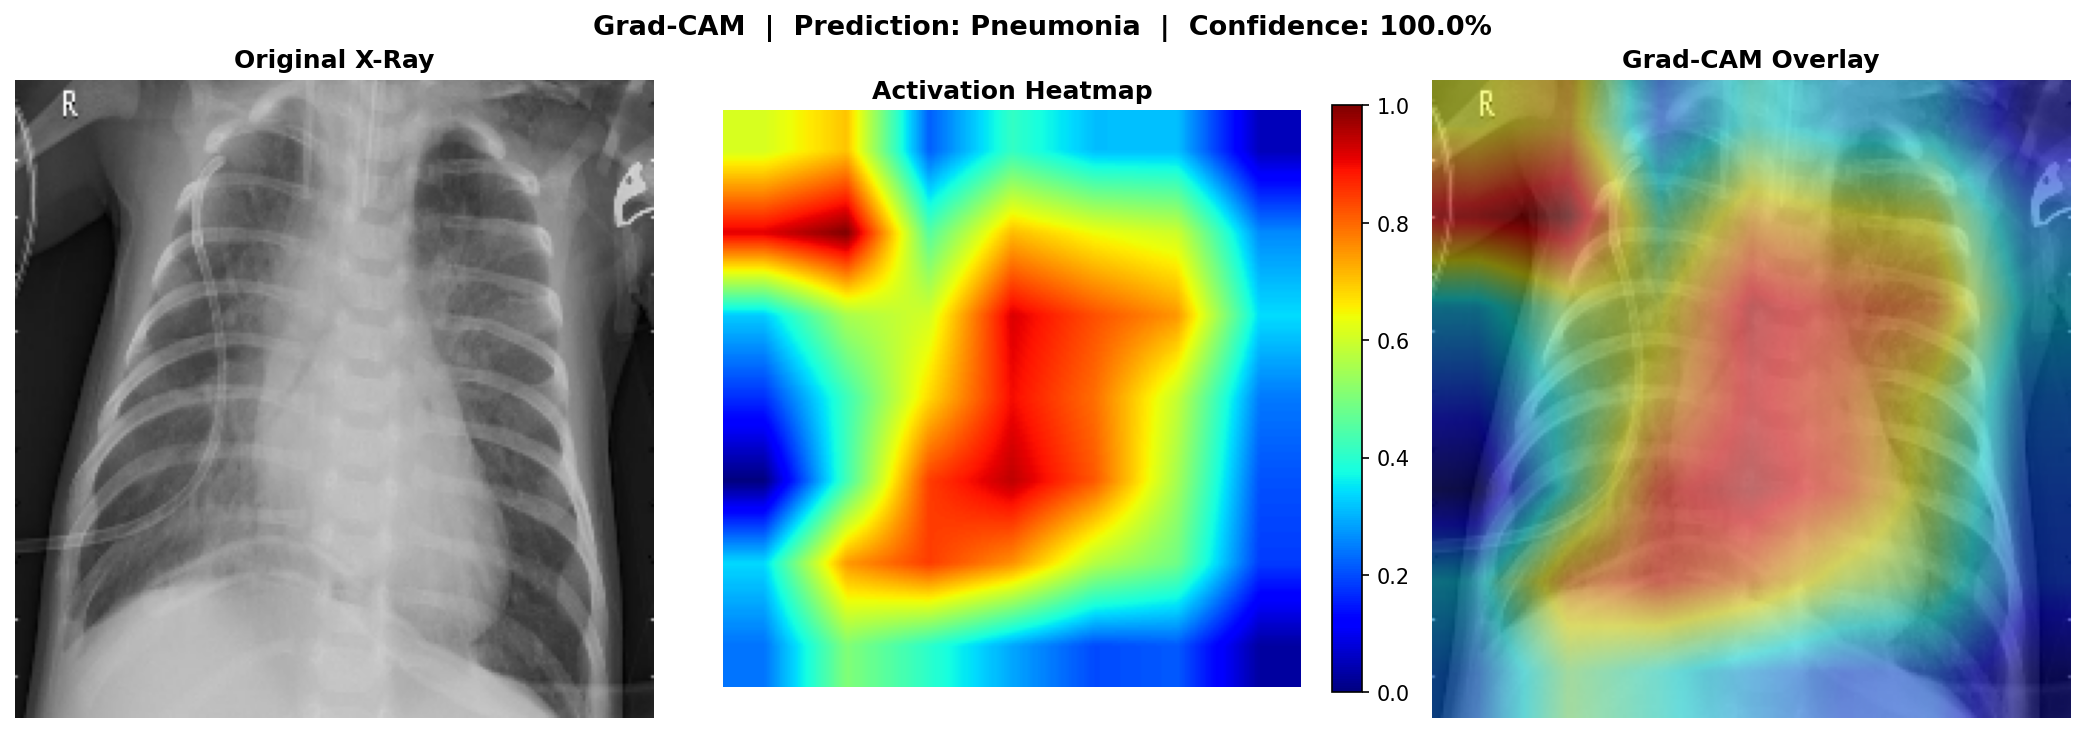

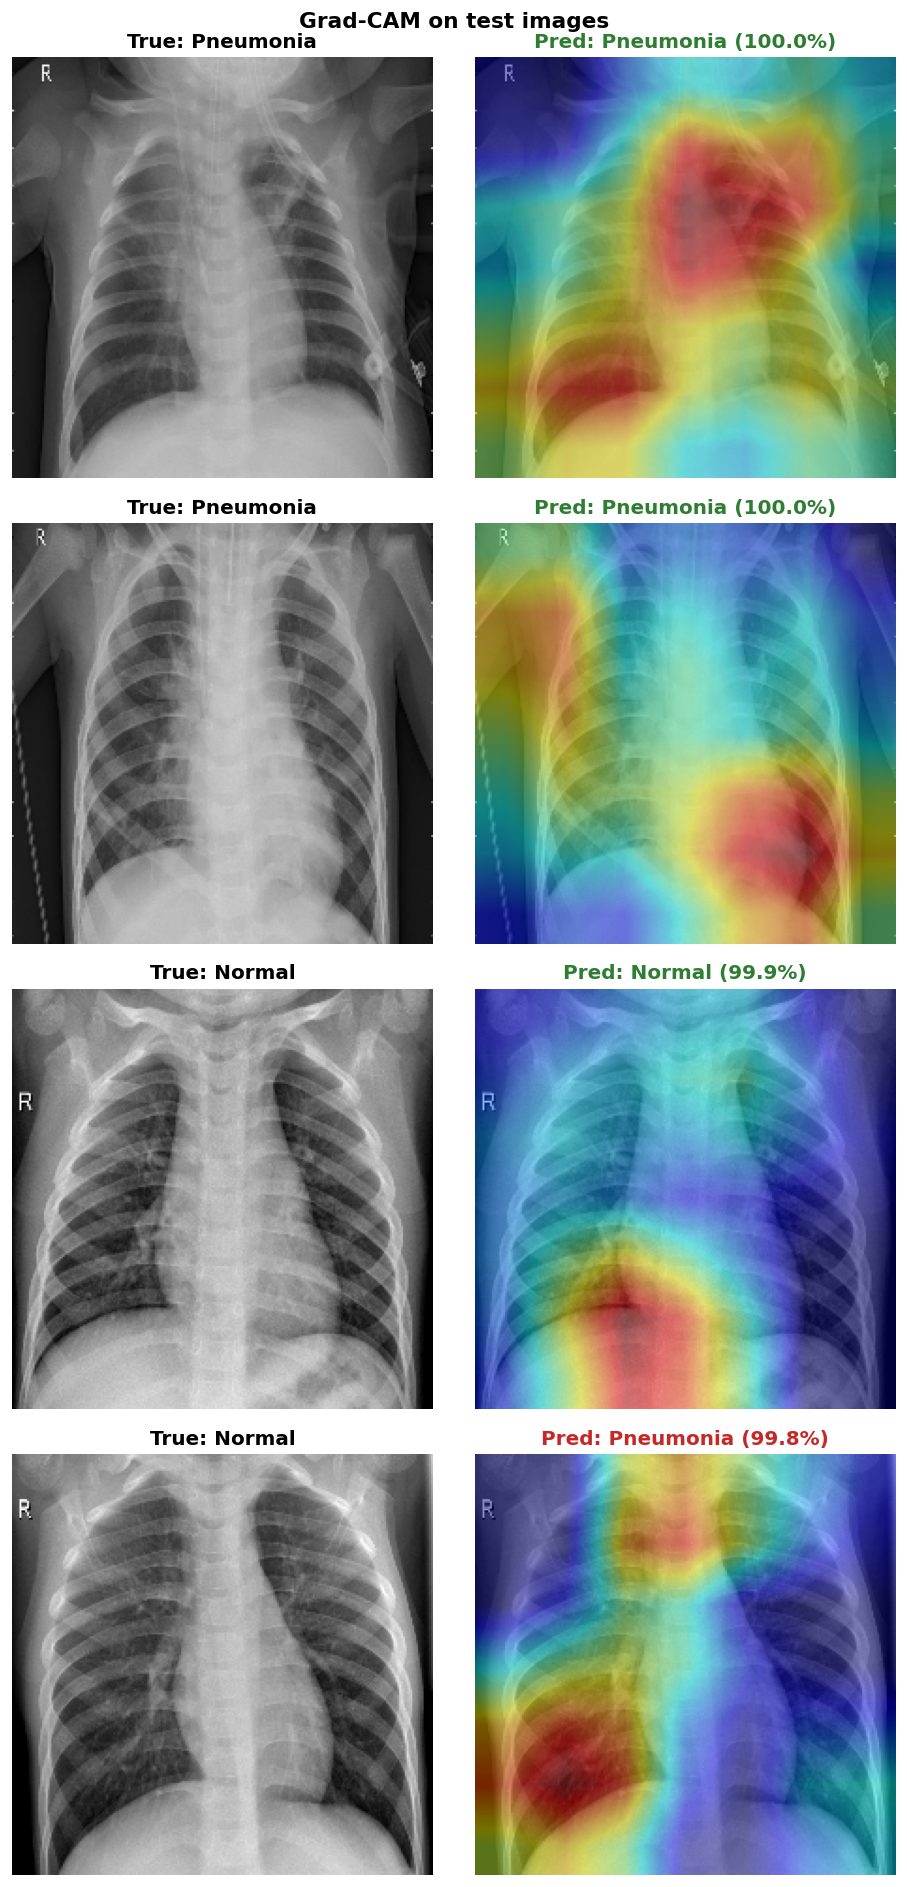

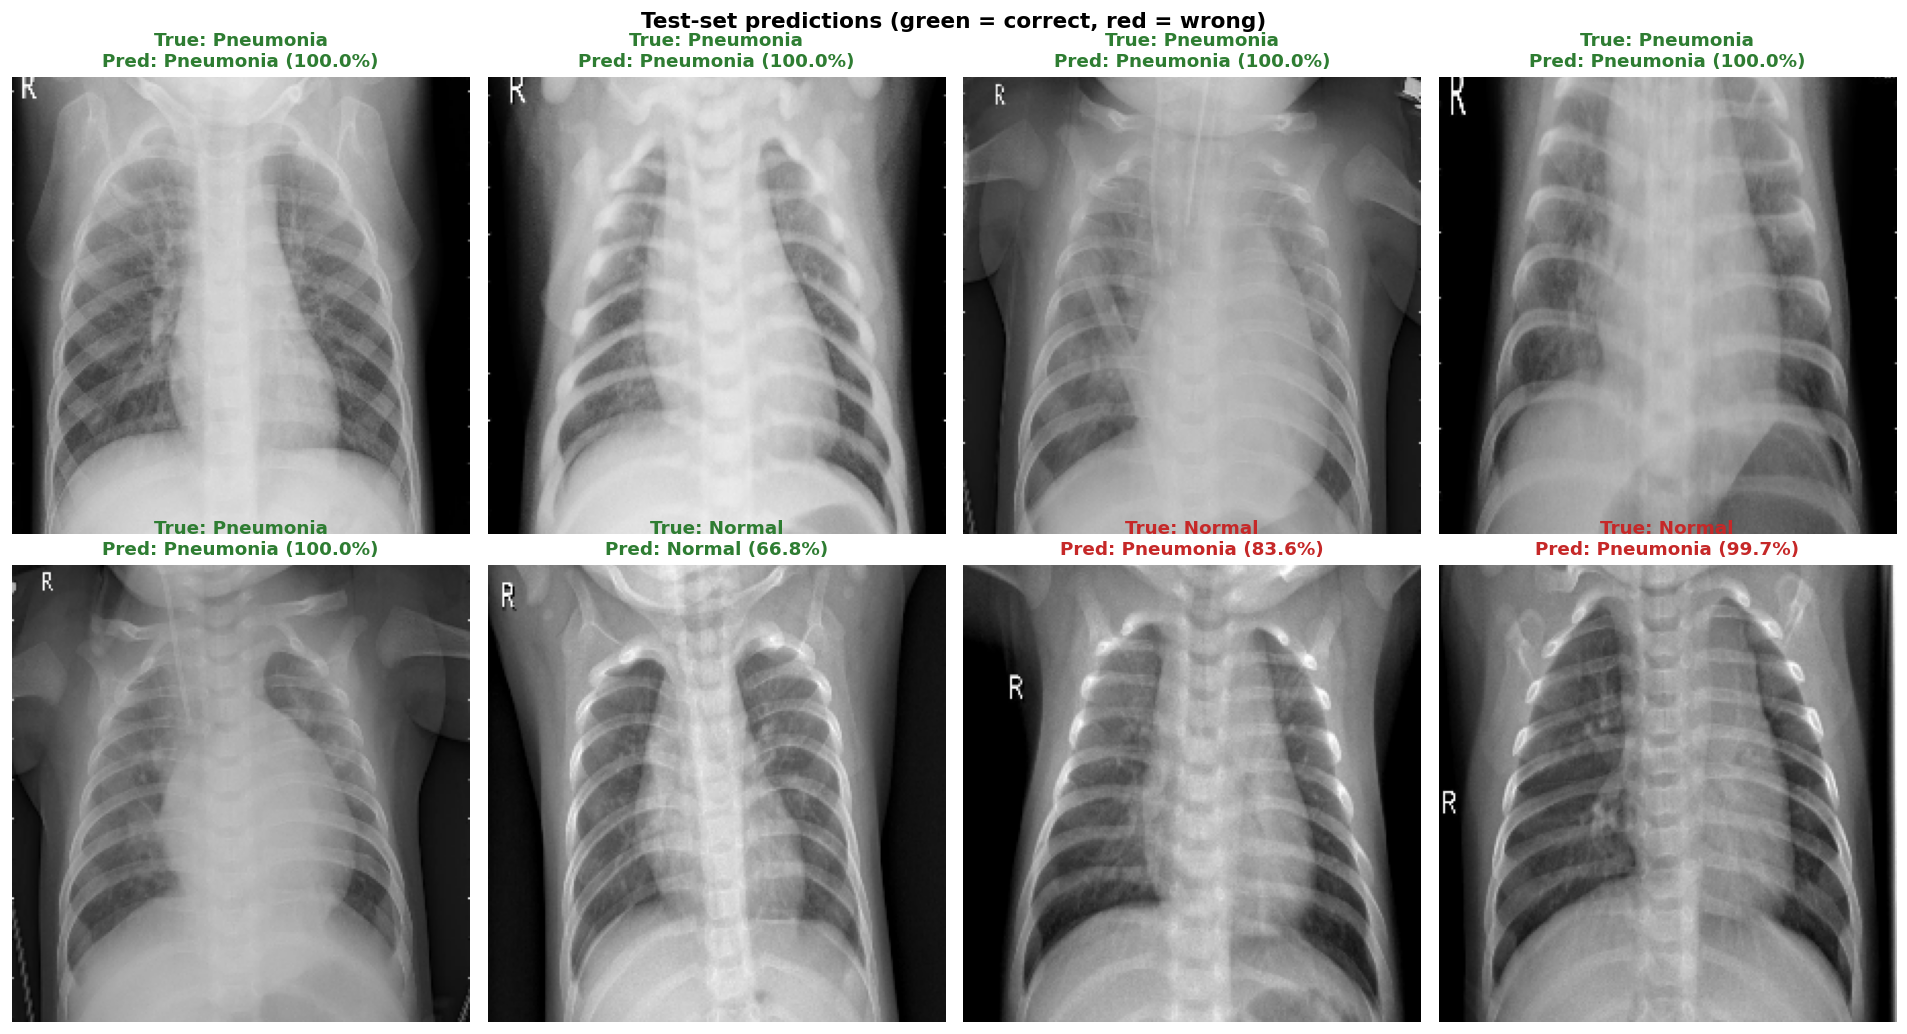

In [7]:
import json
from IPython.display import Image, display

m = json.load(open("outputs/reports/metrics.json"))
print(json.dumps({k: round(v, 4) for k, v in m["metrics"].items()}, indent=2))
print("Confusion matrix:", m["confusion_matrix"])
print("Best epoch:", m.get("best_epoch"), "of", m.get("epochs_trained"))

for name in ["training_curves", "confusion_matrix", "roc_curve", "gradcam_example",
             "gradcam_examples", "prediction_examples"]:
    display(Image(f"outputs/visualizations/{name}.png", width=900))

## 6. Download the results

Send `results.zip` and this notebook (*File → Download → Download .ipynb*) back so they can be committed to the repo.

In [8]:
!rm -f results.zip
!zip -qr results.zip outputs/visualizations outputs/reports outputs/logs/history.csv outputs/logs/history.json
!ls -lh results.zip
from google.colab import files
files.download("results.zip")

-rw-r--r-- 1 root root 4.1M Oct 20 12:02 results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Optional: the trained model (about 100 MB with optimizer state)
# files.download("outputs/models/best_model.keras")